# 02 · Modelo de dados dimensional (SQLite)

**Autor:** Igor Seberino · **Fase CRISP-DM:** preparação dos dados

Objetivo da etapa: organizar o DataFrame preparado no notebook 01 num **modelo de dados
analítico** — um esquema estrela em SQLite — conferir a integridade da carga contra a origem e
responder perguntas de negócio sobre falhas com consultas SQL.

In [1]:
# Ambiente: coloca src/ no sys.path (o notebook roda a partir de notebooks/ ou da raiz)
import sys
from pathlib import Path

RAIZ = next(p for p in (Path.cwd(), Path.cwd().parent) if (p / "pyproject.toml").exists())
sys.path.insert(0, str(RAIZ / "src"))

In [2]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from manutencao import modelo_dados as md
from manutencao.config import CAMINHO_DB
from manutencao.preparacao import carregar_preparado
from manutencao.util import configurar_graficos, salvar_figura, salvar_tabela

configurar_graficos()
pd.set_option("display.max_columns", 30)

## 1. Por que um modelo dimensional

O enunciado pede "construir modelos de dados". Além do modelo preditivo (notebook 04), o grupo
entrega um **modelo de dados analítico** no formato **esquema estrela** (KIMBALL; ROSS, 2013),
que é como dados de sensores de chão de fábrica costumam ser organizados para BI.

- **Grão** da fato: 1 linha = 1 ciclo de processo (`udi`).
- `id_produto` é único por linha (10.000 valores) → **dimensão degenerada**: fica na fato, porque
  uma tabela de produto teria 1 linha por fato, sem ganho.
- `dim_tipo_produto` guarda atributos do tipo, inclusive o **limite de esforço** (11/12/13 mil
  min·Nm), o que permite consultas como "ciclos acima do limite do seu tipo".
- `dim_faixa_desgaste` é uma **dimensão de faixas** (*band dimension*) para agrupar o desgaste.
- Um ciclo pode ter mais de um modo de falha → relação N:N → **tabela ponte** `ponte_ciclo_modo`.
- O dataset não tem data/hora → **não existe dimensão de tempo** (limitação).
- SQLite vem com o Python (`sqlite3`): nenhuma instalação.

```mermaid
erDiagram
    dim_tipo_produto ||--o{ fato_ciclo : "classifica"
    dim_faixa_desgaste ||--o{ fato_ciclo : "agrupa"
    fato_ciclo ||--o{ ponte_ciclo_modo : "registra"
    dim_modo_falha ||--o{ ponte_ciclo_modo : "descreve"
    dim_tipo_produto {
        INTEGER id_tipo PK
        TEXT codigo "L, M, H"
        TEXT descricao
        REAL participacao_nominal
        REAL limite_esforco_min_nm
    }
    dim_faixa_desgaste {
        INTEGER id_faixa PK
        TEXT rotulo
        INTEGER minimo_min
        INTEGER maximo_min
    }
    dim_modo_falha {
        INTEGER id_modo PK
        TEXT sigla "TWF HDF PWF OSF RNF"
        TEXT nome
        TEXT regra
    }
    fato_ciclo {
        INTEGER udi PK
        TEXT id_produto "dimensão degenerada"
        INTEGER id_tipo FK
        INTEGER id_faixa FK
        REAL temp_ar_k
        REAL temp_processo_k
        INTEGER rotacao_rpm
        REAL torque_nm
        INTEGER desgaste_ferramenta_min
        REAL dif_temperatura_k
        REAL potencia_w
        REAL esforco_ferramenta_min_nm
        INTEGER falha
    }
    ponte_ciclo_modo {
        INTEGER udi PK, FK
        INTEGER id_modo PK, FK
    }
```

In [3]:
df = carregar_preparado()
caminho = md.construir_banco(df)
conn = md.conectar(caminho)
print(caminho.relative_to(RAIZ), "recriado a partir de", len(df), "ciclos")

data\processed\industria40.db recriado a partir de 10000 ciclos


In [4]:
md.consultar(
    conn,
    "SELECT type, name, sql FROM sqlite_master "
    "WHERE name NOT LIKE 'sqlite_%' ORDER BY type DESC, name",
)

,type,name,sql
0,table,dim_faixa_desgaste,CREATE TABLE dim_faixa_desgaste (\n id_faix...
1,table,dim_modo_falha,CREATE TABLE dim_modo_falha (\n id_modo ...
2,table,dim_tipo_produto,CREATE TABLE dim_tipo_produto (\n id_tipo ...
3,table,fato_ciclo,CREATE TABLE fato_ciclo (\n udi ...
4,table,ponte_ciclo_modo,CREATE TABLE ponte_ciclo_modo (\n udi ...
5,index,ix_fato_faixa,CREATE INDEX ix_fato_faixa ON fato_ciclo (id_...
6,index,ix_fato_tipo,CREATE INDEX ix_fato_tipo ON fato_ciclo (id_...
7,index,ix_ponte_modo,CREATE INDEX ix_ponte_modo ON ponte_ciclo_mod...


In [5]:
tabelas = [
    "dim_tipo_produto",
    "dim_faixa_desgaste",
    "dim_modo_falha",
    "fato_ciclo",
    "ponte_ciclo_modo",
]
volume = pd.DataFrame(
    {
        "tabela": tabelas,
        "linhas": [conn.execute(f"SELECT COUNT(*) FROM {t}").fetchone()[0] for t in tabelas],
    }
)
salvar_tabela(volume, "02_volume_tabelas")
volume

,tabela,linhas
0,dim_tipo_produto,3
1,dim_faixa_desgaste,5
2,dim_modo_falha,5
3,fato_ciclo,10000
4,ponte_ciclo_modo,373


## 2. Integridade da carga

Cada verificação compara o banco com o DataFrame de origem:

- **linhas na fato** = linhas do DataFrame → nenhum ciclo perdido ou duplicado;
- **falhas na fato** = soma do alvo → o rótulo chegou intacto;
- **linhas na ponte** = soma dos 5 modos → cada modo marcado virou exatamente uma linha;
- **violações de chave estrangeira** = 0 → toda fato aponta para dimensões existentes;
- **ciclos sem tipo** = 0 → nenhum código de tipo ficou sem correspondência;
- **soma do torque** confere → os valores numéricos não foram truncados na carga.

In [6]:
integ = md.verificar_integridade(conn, df)
salvar_tabela(integ, "02_integridade")
assert integ["ok"].all()
integ

,verificacao,esperado,obtido,ok
0,linhas na fato = linhas do DataFrame,10000.0,10000.0,True
1,falhas na fato = soma do alvo,339.0,339.0,True
2,linhas na ponte = soma dos 5 modos,373.0,373.0,True
3,violações de chave estrangeira,0.0,0.0,True
4,ciclos sem tipo,0.0,0.0,True
5,soma do torque confere,399869.1,399869.1,True


## 3. Consultas analíticas

| Consulta | Pergunta de negócio |
|---|---|
| `taxa_falha_por_tipo` | A qualidade do produto (L/M/H) muda a chance de falha? |
| `falhas_por_modo` | Quais modos de falha mais ocorrem? |
| `coocorrencia_modos` | Quais modos aparecem juntos no mesmo ciclo? |
| `taxa_falha_por_faixa_desgaste` | A partir de quanto desgaste a ferramenta passa a falhar mais? |
| `taxa_falha_por_tipo_e_faixa` | O efeito do desgaste é igual para todos os tipos? |
| `perfil_sensores_por_modo` | O que os sensores mostram de diferente em cada modo de falha? |
| `esforco_acima_do_limite` | O limite de esforço do tipo explica a sobrecarga (OSF)? |
| `inconsistencias_rotulo` | O banco preserva as inconsistências de rótulo do notebook 01? |

In [7]:
resultados = md.executar_consultas(conn)
for nome, tab in resultados.items():
    salvar_tabela(tab, f"02_{nome}")
sorted(resultados)

['coocorrencia_modos',
 'esforco_acima_do_limite',
 'falhas_por_modo',
 'inconsistencias_rotulo',
 'perfil_sensores_por_modo',
 'taxa_falha_por_faixa_desgaste',
 'taxa_falha_por_tipo',
 'taxa_falha_por_tipo_e_faixa']


        SELECT t.codigo AS tipo, t.descricao, COUNT(*) AS ciclos, SUM(f.falha) AS falhas,
               ROUND(100.0 * SUM(f.falha) / COUNT(*), 2) AS taxa_falha_pct
        FROM fato_ciclo f JOIN dim_tipo_produto t ON t.id_tipo = f.id_tipo
        GROUP BY t.id_tipo ORDER BY t.id_tipo


,tipo,descricao,ciclos,falhas,taxa_falha_pct
0,L,Baixa qualidade,6000,235,3.92
1,M,Média qualidade,2997,83,2.77
2,H,Alta qualidade,1003,21,2.09


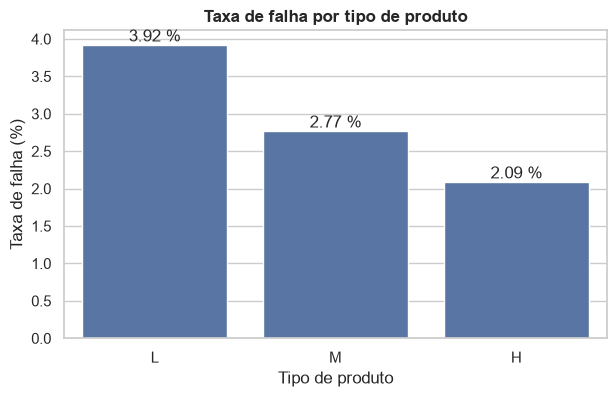

In [8]:
print(md.CONSULTAS["taxa_falha_por_tipo"])
t = resultados["taxa_falha_por_tipo"]
fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(data=t, x="tipo", y="taxa_falha_pct", ax=ax)
ax.bar_label(ax.containers[0], fmt="%.2f %%")
ax.set(
    title="Taxa de falha por tipo de produto",
    xlabel="Tipo de produto",
    ylabel="Taxa de falha (%)",
)
salvar_figura(fig, "02_taxa_falha_por_tipo")
t


        SELECT m.sigla, m.nome, COUNT(*) AS ocorrencias,
               ROUND(100.0 * COUNT(*) / (SELECT SUM(falha) FROM fato_ciclo), 2)
                   AS pct_sobre_falhas
        FROM ponte_ciclo_modo p JOIN dim_modo_falha m ON m.id_modo = p.id_modo
        GROUP BY m.id_modo ORDER BY ocorrencias DESC


,sigla,nome,ocorrencias,pct_sobre_falhas
0,HDF,Dissipação de calor,115,33.92
1,OSF,Sobrecarga,98,28.91
2,PWF,Potência,95,28.02
3,TWF,Desgaste da ferramenta,46,13.57
4,RNF,Aleatória,19,5.60


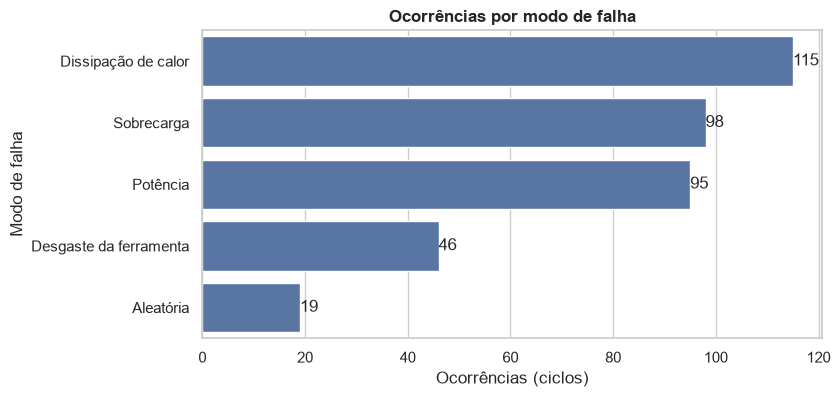

In [9]:
print(md.CONSULTAS["falhas_por_modo"])
t = resultados["falhas_por_modo"]
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=t, y="nome", x="ocorrencias", ax=ax)
ax.bar_label(ax.containers[0])
ax.set(
    title="Ocorrências por modo de falha",
    xlabel="Ocorrências (ciclos)",
    ylabel="Modo de falha",
)
salvar_figura(fig, "02_falhas_por_modo")
t

In [10]:
print(md.CONSULTAS["coocorrencia_modos"])
t = resultados["coocorrencia_modos"]
multi = md.consultar(
    conn,
    "SELECT COUNT(*) AS ciclos FROM "
    "(SELECT udi FROM ponte_ciclo_modo GROUP BY udi HAVING COUNT(*) > 1)",
)
print("ciclos com mais de um modo:", int(multi.iloc[0, 0]))
t


        SELECT a.sigla AS modo_a, b.sigla AS modo_b, COUNT(*) AS ciclos
        FROM ponte_ciclo_modo pa
        JOIN ponte_ciclo_modo pb ON pb.udi = pa.udi AND pb.id_modo > pa.id_modo
        JOIN dim_modo_falha a ON a.id_modo = pa.id_modo
        JOIN dim_modo_falha b ON b.id_modo = pb.id_modo
        GROUP BY a.sigla, b.sigla ORDER BY ciclos DESC
ciclos com mais de um modo: 24


,modo_a,modo_b,ciclos
0,PWF,OSF,12
1,HDF,OSF,6
2,HDF,PWF,3
3,TWF,OSF,3
4,TWF,PWF,1
5,TWF,RNF,1



        SELECT d.rotulo AS faixa_desgaste, COUNT(*) AS ciclos, SUM(f.falha) AS falhas,
               ROUND(100.0 * SUM(f.falha) / COUNT(*), 2) AS taxa_falha_pct
        FROM fato_ciclo f JOIN dim_faixa_desgaste d ON d.id_faixa = f.id_faixa
        GROUP BY d.id_faixa ORDER BY d.id_faixa


,faixa_desgaste,ciclos,falhas,taxa_falha_pct
0,000-049 min,2349,52,2.21
1,050-099 min,2271,51,2.25
2,100-149 min,2290,52,2.27
3,150-199 min,2289,61,2.66
4,200+ min,801,123,15.36


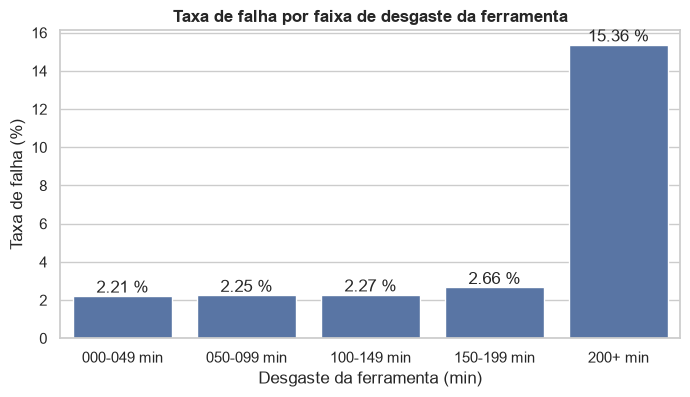

In [11]:
print(md.CONSULTAS["taxa_falha_por_faixa_desgaste"])
t = resultados["taxa_falha_por_faixa_desgaste"]
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=t, x="faixa_desgaste", y="taxa_falha_pct", ax=ax)
ax.bar_label(ax.containers[0], fmt="%.2f %%")
ax.set(
    title="Taxa de falha por faixa de desgaste da ferramenta",
    xlabel="Desgaste da ferramenta (min)",
    ylabel="Taxa de falha (%)",
)
salvar_figura(fig, "02_taxa_falha_por_faixa_desgaste")
t


        SELECT t.codigo AS tipo, d.rotulo AS faixa_desgaste, COUNT(*) AS ciclos,
               SUM(f.falha) AS falhas, ROUND(100.0 * SUM(f.falha) / COUNT(*), 2) AS taxa_falha_pct
        FROM fato_ciclo f
        JOIN dim_tipo_produto t ON t.id_tipo = f.id_tipo
        JOIN dim_faixa_desgaste d ON d.id_faixa = f.id_faixa
        GROUP BY t.id_tipo, d.id_faixa ORDER BY t.id_tipo, d.id_faixa


faixa_desgaste,000-049 min,050-099 min,100-149 min,150-199 min,200+ min
tipo,,,,,
L,2.48,2.54,1.96,3.44,18.29
M,1.99,2.16,2.79,1.73,10.31
H,1.29,0.85,2.60,0.87,10.67


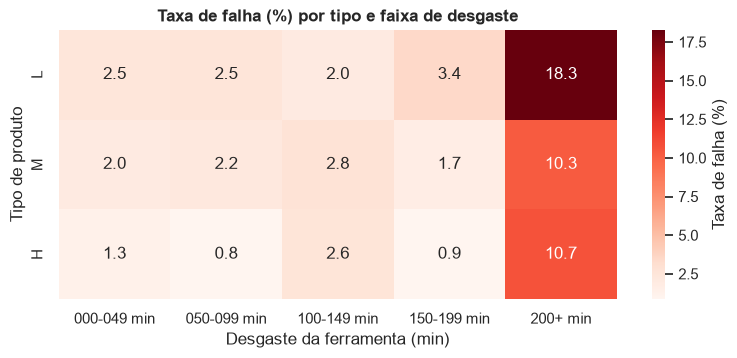

In [12]:
print(md.CONSULTAS["taxa_falha_por_tipo_e_faixa"])
t = resultados["taxa_falha_por_tipo_e_faixa"]
pivo = t.pivot(index="tipo", columns="faixa_desgaste", values="taxa_falha_pct").loc[["L", "M", "H"]]
fig, ax = plt.subplots(figsize=(9, 3.5))
sns.heatmap(
    pivo, annot=True, fmt=".1f", cmap="Reds", cbar_kws={"label": "Taxa de falha (%)"}, ax=ax
)
ax.set(
    title="Taxa de falha (%) por tipo e faixa de desgaste",
    xlabel="Desgaste da ferramenta (min)",
    ylabel="Tipo de produto",
)
salvar_figura(fig, "02_heatmap_tipo_faixa")
pivo

In [13]:
print(md.CONSULTAS["perfil_sensores_por_modo"])
resultados["perfil_sensores_por_modo"]


        SELECT m.sigla, COUNT(*) AS ciclos,
               ROUND(AVG(f.dif_temperatura_k), 2) AS dif_temp_media_k,
               ROUND(AVG(f.rotacao_rpm), 0) AS rotacao_media_rpm,
               ROUND(AVG(f.torque_nm), 1) AS torque_medio_nm,
               ROUND(AVG(f.potencia_w), 0) AS potencia_media_w,
               ROUND(AVG(f.desgaste_ferramenta_min), 0) AS desgaste_medio_min
        FROM ponte_ciclo_modo p
        JOIN fato_ciclo f ON f.udi = p.udi
        JOIN dim_modo_falha m ON m.id_modo = p.id_modo
        GROUP BY m.id_modo
        UNION ALL
        SELECT 'SEM FALHA', COUNT(*), ROUND(AVG(dif_temperatura_k), 2), ROUND(AVG(rotacao_rpm), 0),
               ROUND(AVG(torque_nm), 1), ROUND(AVG(potencia_w), 0),
               ROUND(AVG(desgaste_ferramenta_min), 0)
        FROM fato_ciclo WHERE falha = 0


,sigla,ciclos,dif_temp_media_k,rotacao_media_rpm,torque_medio_nm,potencia_media_w,desgaste_medio_min
0,TWF,46,9.87,1566.0,37.8,6019.0,216.0
1,HDF,115,8.23,1337.0,53.2,7433.0,107.0
2,PWF,95,9.88,1764.0,48.5,7252.0,102.0
3,OSF,98,10.03,1350.0,58.4,8230.0,208.0
4,RNF,19,9.95,1485.0,43.7,6686.0,124.0
5,SEM FALHA,9661,10.02,1540.0,39.6,6245.0,107.0


In [14]:
print(md.CONSULTAS["esforco_acima_do_limite"])
t = resultados["esforco_acima_do_limite"]
assert (t["ciclos_acima"] == t["ciclos_com_osf"]).all()
t


        SELECT t.codigo AS tipo, t.limite_esforco_min_nm,
               SUM(f.esforco_ferramenta_min_nm > t.limite_esforco_min_nm) AS ciclos_acima,
               SUM(CASE WHEN f.esforco_ferramenta_min_nm > t.limite_esforco_min_nm
                        THEN f.falha ELSE 0 END) AS falhas_acima,
               SUM(EXISTS (SELECT 1 FROM ponte_ciclo_modo p
                           WHERE p.udi = f.udi AND p.id_modo = 4)) AS ciclos_com_osf
        FROM fato_ciclo f JOIN dim_tipo_produto t ON t.id_tipo = f.id_tipo
        GROUP BY t.id_tipo ORDER BY t.id_tipo


,tipo,limite_esforco_min_nm,ciclos_acima,falhas_acima,ciclos_com_osf
0,L,11000.0,87,87,87
1,M,12000.0,9,9,9
2,H,13000.0,2,2,2


In [15]:
print(md.CONSULTAS["inconsistencias_rotulo"])
resultados["inconsistencias_rotulo"]


        SELECT 'falha sem modo' AS inconsistencia, COUNT(*) AS ciclos
        FROM fato_ciclo f
        WHERE f.falha = 1 AND NOT EXISTS (SELECT 1 FROM ponte_ciclo_modo p WHERE p.udi = f.udi)
        UNION ALL
        SELECT 'modo sem falha', COUNT(DISTINCT p.udi)
        FROM ponte_ciclo_modo p JOIN fato_ciclo f ON f.udi = p.udi
        WHERE f.falha = 0


,inconsistencia,ciclos
0,falha sem modo,9
1,modo sem falha,18


In [16]:
conn.close()

## Conclusões da etapa

- A carga passou nas **6 verificações de integridade** (`02_integridade.csv`): 10.000 ciclos na
  fato, 339 falhas, 373 linhas na ponte (soma dos 5 modos), zero violação de chave estrangeira.
- O **desgaste** separa o risco de forma abrupta: até 199 min a taxa de falha fica entre 2,21 % e
  2,66 %; na faixa **200+ min** salta para **15,36 %** (123 falhas em 801 ciclos). No tipo L
  essa faixa chega a **18,29 %** (`02_taxa_falha_por_tipo_e_faixa.csv`).
- A taxa cai com a qualidade do produto: **L 3,92 %**, M 2,77 %, H 2,09 %
  (`02_taxa_falha_por_tipo.csv`).
- **HDF** é o modo mais frequente (115 ocorrências, 33,92 % das falhas), seguido de OSF (98) e
  PWF (95); **24 ciclos** têm mais de um modo, sendo PWF + OSF o par mais comum (12 ciclos).
- O atributo `limite_esforco_min_nm` da dimensão de tipo **explica 100 % da sobrecarga**: os
  98 ciclos acima do limite do seu tipo são exatamente os 98 ciclos com OSF (87 L, 9 M, 2 H).
- O perfil de sensores mostra assinaturas distintas: TWF e OSF ocorrem com desgaste médio de
  216 e 208 min (107 min nos ciclos sem falha); HDF com diferença de temperatura de 8,23 K e
  rotação de 1.337 rpm (10,02 K e 1.540 rpm sem falha).
- O banco preserva as **inconsistências de rótulo** do notebook 01 (9 "falha sem modo" e
  18 "modo sem falha"), o que confirma que a modelagem não alterou os dados.
- Limitação: sem data/hora no dataset, não há dimensão de tempo — não dá para analisar tendência
  ao longo do turno ou da semana.
